# 3. DSMC against the mean field

The mean-field model rests on two limits: many agents ($N\to\infty$) and perceived values that relax much
faster than purchases happen (time-scale separation). This notebook checks how the agent-based DSMC
approaches the mean field in each limit.

The DSMC trajectories come from `scripts/run_experiments.py` (CSV files in `results/`); the last check runs
live. The relaxation speed is controlled by the interaction rate $\mu_c$ (interactions per agent per unit
time), raised with the per-collision coefficients of `Params()` unchanged; $\mu_c$ is the same symbol as in the paper.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import invgamma

from kinetic_hype import Params, Signals, fixed_signals, dsmc, meanfield as mf
from kinetic_hype.plotting import use_style, plot_trajectory, QUANTITY, INK, INK_2

use_style()
RES = Path("..") / "results"
p, s = Params(), Signals()
ref = pd.read_csv(RES / "meanfield_default.csv")
speed = pd.read_csv(RES / "trajectories_speed.csv")
conv = pd.read_csv(RES / "convergence_speed.csv")
size = pd.read_csv(RES / "trajectories_size.csv")
print("interaction rates mu_c:", [int(m) for m in sorted(speed.mu_c.unique())], "  N values:", [int(n) for n in sorted(size.N.unique())])

interaction rates mu_c: [500, 1000, 2000, 4000, 8000, 16000, 32000]   N values: [500, 2000, 8000, 32000]


## Is the default parameter set in the separated regime?

The mean of non-users' values is pulled towards the media message at rate $\mu_c\, b\,\mu(t)$ and towards
users' reports at rate $\mu_c\, a_2 \rho$ (interactions among non-users conserve the mean). Purchases happen at
rate $\lambda$. Time-scale separation needs the first two to be much larger than $\lambda$.

mu_c = 1000: ratio at t=0 0.17, max 8.82, at t=10 8.82


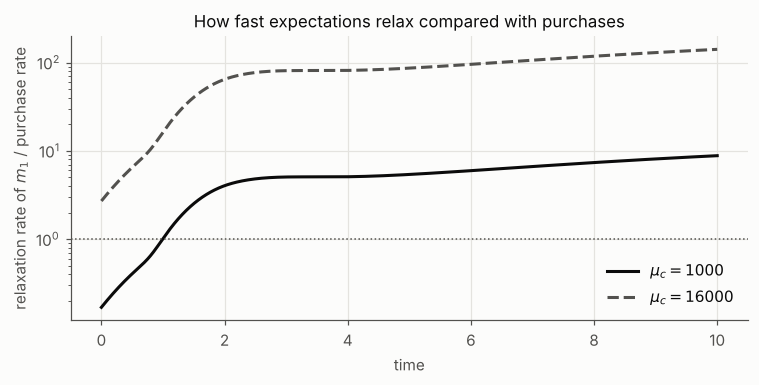

In [2]:
t = ref.t.to_numpy()
relax = 1000 * (p.b * ref.media + p.a2 * ref.rho)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(t, relax / p.lam, color=INK, label=r"$\mu_c=1000$")
ax.plot(t, 16 * relax / p.lam, color=INK_2, ls="--", label=r"$\mu_c=16000$")
ax.axhline(1, color=INK_2, ls=":", lw=1)
ax.set_yscale("log"); ax.set_xlabel("time")
ax.set_ylabel("relaxation rate of $m_1$ / purchase rate")
ax.set_title("How fast expectations relax compared with purchases"); ax.legend()
fig.tight_layout()
print(f"mu_c = 1000: ratio at t=0 {relax.iloc[0]/p.lam:.2f}, max {relax.max()/p.lam:.2f}, at t=10 {relax.iloc[-1]/p.lam:.2f}")

At $\mu_c=1000$ the ratio starts far below one (weak media, no users) and reaches about 9 only
late in the run, once a large share has adopted and users' reports dominate. Expectations therefore do not relax much faster
than purchases during the phase that matters for the hype cycle. Results computed with the mean field
describe the fast-relaxation limit, not the $\mu_c=1000$ agents. This is a property of the parameter set, not of
the numerics.

## Trajectories as relaxation speeds up

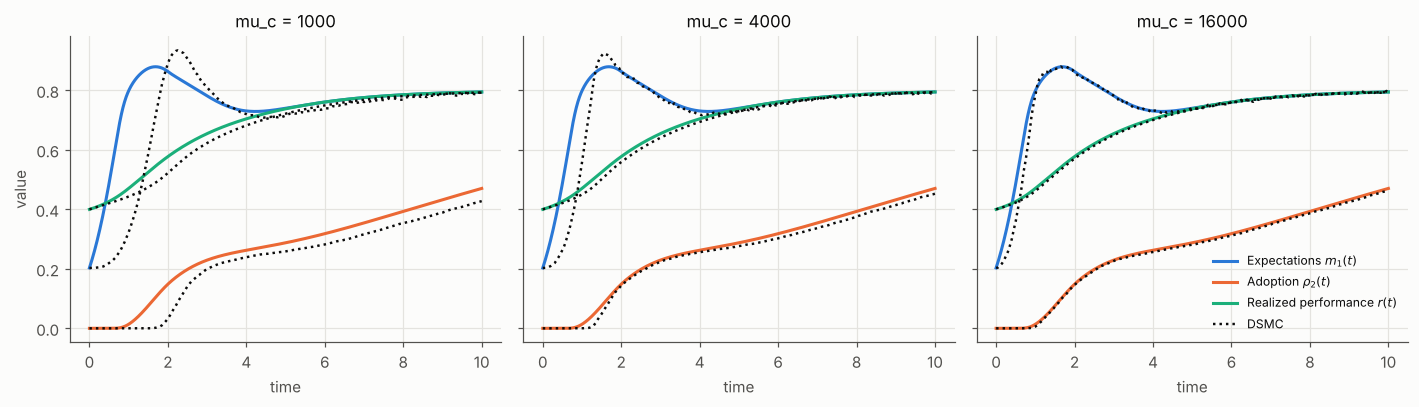

In [3]:
rates = [1000, 4000, 16000]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, m in zip(axes, rates):
    d = speed[speed.mu_c == m]
    plot_trajectory(ax, ref, dsmc=d)
    ax.set_title(f"mu_c = {m}")
axes[0].set_ylabel("value"); axes[-1].legend(loc="lower right", fontsize=8)
fig.tight_layout()

Solid: mean field. Dotted: DSMC, $N=10^4$, one seed. The DSMC expectations lag the mean field, which
jumps to the moving equilibrium instantly; the lag shrinks as $\mu_c$ grows.

rho            -0.84
rho_after_t1   -0.85
m1             -0.64
m1_after_t1    -1.15
r              -0.69
r_after_t1     -0.72
Name: log-log slope (mu_c >= 2000), dtype: float64

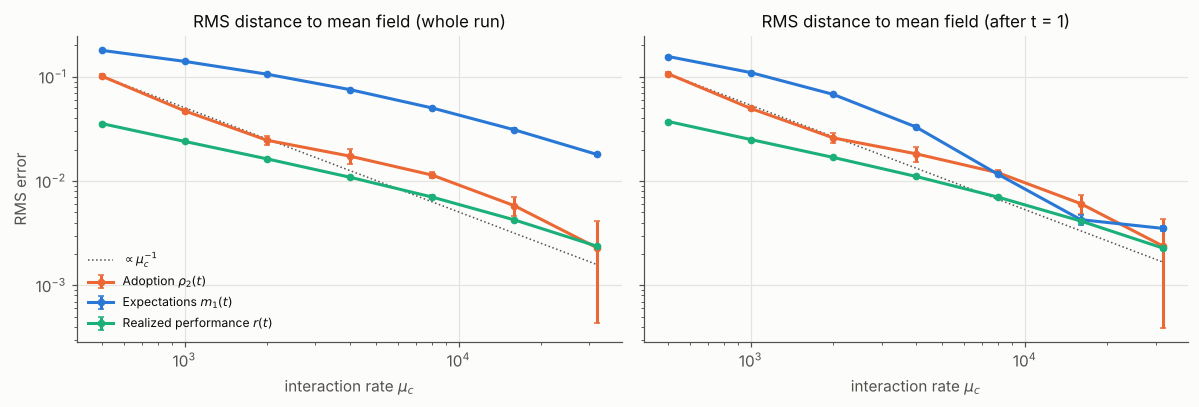

In [4]:
g = conv.groupby("mu_c").agg(["mean", "std"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, suffix, title in [(axes[0], "", "whole run"), (axes[1], "_after_t1", "after t = 1")]:
    for c in ["rho", "m1", "r"]:
        m, sd = g[f"rms_{c}{suffix}"]["mean"], g[f"rms_{c}{suffix}"]["std"]
        ax.errorbar(g.index, m, yerr=sd, marker="o", ms=4, capsize=2, color=QUANTITY[c]["color"],
                    label=QUANTITY[c]["label"])
    mm = np.array([g.index.min(), g.index.max()], dtype=float)
    ax.plot(mm, g[f"rms_rho{suffix}"]["mean"].iloc[0] * mm[0] / mm, color=INK_2, ls=":", lw=1, label=r"$\propto \mu_c^{-1}$")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"interaction rate $\mu_c$")
    ax.set_title(f"RMS distance to mean field ({title})")
axes[0].set_ylabel("RMS error"); axes[0].legend(fontsize=8)
fig.tight_layout()

slopes = {}
for c in ["rho", "m1", "r"]:
    for suffix in ["", "_after_t1"]:
        y = g[f"rms_{c}{suffix}"]["mean"]
        sel = y.index >= 2000
        slopes[f"{c}{suffix}"] = np.polyfit(np.log(y.index[sel]), np.log(y[sel]), 1)[0]
pd.Series(slopes, name="log-log slope (mu_c >= 2000)").round(2)

**Reading the plot.** The errors fall steadily with $\mu_c$. After the initial transient, the expectations error
falls like $\mu_c^{-1}$ (fitted slope about $-1.1$ for $\mu_c\ge2000$), as expected for a lag inversely proportional to
the relaxation rate. Adoption and realized performance converge more slowly (slopes $-0.72$ to $-0.85$),
because they integrate the early lag. Including $t<1$, where relaxation is slowest, the expectations slope
is only about $-0.6$. Error bars are standard deviations across three seeds.

## Finite population

At fixed relaxation speed ($\mu_c=8000$), the spread of DSMC trajectories across seeds should shrink like
$N^{-1/2}$. Six seeds per $N$ give a rough estimate of a standard deviation (relative error about 30%).

,sd_rho_final,sd_m1_mean
N,,
500,0.00700,0.01708
2000,0.00717,0.00751
8000,0.00315,0.00391
32000,0.00208,0.00180


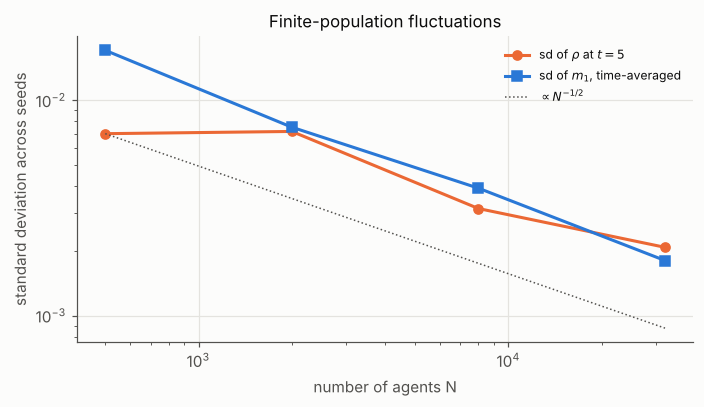

In [5]:
rows = []
for N, d in size.groupby("N"):
    wide_rho = d.pivot(index="t", columns="seed", values="rho")
    wide_m1 = d.pivot(index="t", columns="seed", values="m1")
    rows.append({"N": N, "sd_rho_final": wide_rho.iloc[-1].std(),
                 "sd_m1_mean": wide_m1.std(axis=1).mean()})
fs = pd.DataFrame(rows).set_index("N")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(fs.index, fs.sd_rho_final, "o-", color=QUANTITY["rho"]["color"], label=r"sd of $\rho$ at $t=5$")
ax.plot(fs.index, fs.sd_m1_mean, "s-", color=QUANTITY["m1"]["color"], label=r"sd of $m_1$, time-averaged")
NN = fs.index.to_numpy(dtype=float)
ax.plot(NN, fs.sd_rho_final.iloc[0] * np.sqrt(NN[0] / NN), color=INK_2, ls=":", lw=1, label=r"$\propto N^{-1/2}$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("number of agents N")
ax.set_ylabel("standard deviation across seeds"); ax.set_title("Finite-population fluctuations")
ax.legend(fontsize=8); fig.tight_layout()
fs.round(5)

## Stationary law of the collision kernel

With purchases switched off, constant media and no users, the DSMC's non-users should settle to the
inverse-gamma law of notebook 1. This runs live (about a minute).

share above price: DSMC 0.3488, hazard 0.3464
mean: DSMC 0.9500, inverse gamma 0.9500
std:  DSMC 0.1849, inverse gamma 0.1845


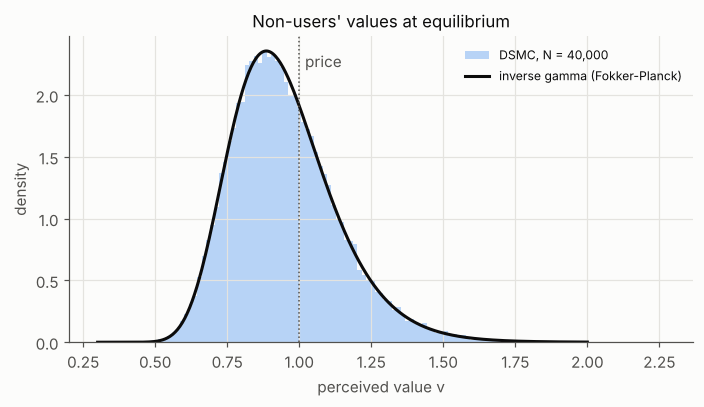

In [6]:
pq = Params(lam=1e-9)
sq = fixed_signals(media=1.0, message=0.95)
rng = np.random.default_rng(4)
v = dsmc.initial_values(40_000, pq, sq, rng, init="message")
user = np.zeros(v.size, dtype=bool)
sd = np.sqrt(pq.eta)
for _ in range(3000):                       # 3 time units at mu_c = 1000
    perm = rng.permutation(v.size)
    i, j = perm[: v.size // 2], perm[v.size // 2:]
    vi, vj = v[i], v[j]
    v[i] = dsmc._update(vi, vj, user[i], user[j], pq, 1.0, 0.95, 1.0, 0.4, sd, sd, rng)
    v[j] = dsmc._update(vj, vi, user[j], user[i], pq, 1.0, 0.95, 1.0, 0.4, sd, sd, rng)

shape, beta = mf.distribution_parameters(0.0, 0.4, 0.0, pq, sq)
x = np.linspace(0.3, 2.0, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(v, bins=120, density=True, color="#b7d3f6", label="DSMC, N = 40,000")
ax.plot(x, invgamma.pdf(x, a=shape, scale=beta), color=INK, label="inverse gamma (Fokker-Planck)")
ax.axvline(1.0, color=INK_2, ls=":", lw=1); ax.text(1.02, ax.get_ylim()[1] * 0.9, "price", color=INK_2)
ax.set_xlabel("perceived value v"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Non-users' values at equilibrium")
fig.tight_layout()
print(f"share above price: DSMC {(v > 1).mean():.4f}, hazard {mf.adoption_hazard(0.0, 0.4, 0.0, pq, sq):.4f}")
print(f"mean: DSMC {v.mean():.4f}, inverse gamma {invgamma.mean(shape, scale=beta):.4f}")
print(f"std:  DSMC {v.std():.4f}, inverse gamma {invgamma.std(shape, scale=beta):.4f}")

**Finite-$N$ result.** The time-averaged spread of $m_1$ follows $N^{-1/2}$ closely (it halves with each fourfold
increase in $N$). The spread of final adoption is noisier: it is flat between $N=500$ and $N=2000$ and then
falls; with six seeds a standard deviation has a relative error of about 30%, so these differences are
within sampling error.

The Fokker–Planck law is the quasi-invariant limit of the collision kernel (small jumps per collision);
with $b=10^{-3}$ the agreement is within sampling error for the share above the price, and close for the
standard deviation. Larger per-collision coefficients would widen the gap.